In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/housing.csv")

In [ ]:
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  object 
 2   price          21613 non-null  int64  
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long  

In [ ]:
df[df['id'].duplicated(keep=False)]

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
93,6021501535,20140725T000000,430000,3,1.50,1580,5000,1.0,0,0,...,8,1290,290,1939,0,98117,47.6870,-122.386,1570,4500
94,6021501535,20141223T000000,700000,3,1.50,1580,5000,1.0,0,0,...,8,1290,290,1939,0,98117,47.6870,-122.386,1570,4500
313,4139480200,20140618T000000,1384000,4,3.25,4290,12103,1.0,0,3,...,11,2690,1600,1997,0,98006,47.5503,-122.102,3860,11244
314,4139480200,20141209T000000,1400000,4,3.25,4290,12103,1.0,0,3,...,11,2690,1600,1997,0,98006,47.5503,-122.102,3860,11244
324,7520000520,20140905T000000,232000,2,1.00,1240,12092,1.0,0,0,...,6,960,280,1922,1984,98146,47.4957,-122.352,1820,7460
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20670,8564860270,20150330T000000,502000,4,2.50,2680,5539,2.0,0,0,...,8,2680,0,2013,0,98045,47.4759,-121.734,2680,5992
20779,6300000226,20140626T000000,240000,4,1.00,1200,2171,1.5,0,0,...,7,1200,0,1933,0,98133,47.7076,-122.342,1130,1598
20780,6300000226,20150504T000000,380000,4,1.00,1200,2171,1.5,0,0,...,7,1200,0,1933,0,98133,47.7076,-122.342,1130,1598
21580,7853420110,20141003T000000,594866,3,3.00,2780,6000,2.0,0,0,...,9,2780,0,2013,0,98065,47.5184,-121.886,2850,6000


In [ ]:
#on inspection, the same house had appeared twice; but the date and price changed
# hence although the id duplicate helped us understand how the data is given, we must drop
# the identifiers as they are pretty much unnecessary
# also, all other columns of houses having the same id are same

In [ ]:
df.drop('id',axis=1,inplace=True)

In [ ]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,20141013T000000,221900,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,20141209T000000,538000,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,20150225T000000,180000,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,20141209T000000,604000,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,20150218T000000,510000,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,20140521T000000,360000,3,2.50,1530,1131,3.0,0,0,3,8,1530,0,2009,0,98103,47.6993,-122.346,1530,1509
21609,20150223T000000,400000,4,2.50,2310,5813,2.0,0,0,3,8,2310,0,2014,0,98146,47.5107,-122.362,1830,7200
21610,20140623T000000,402101,2,0.75,1020,1350,2.0,0,0,3,7,1020,0,2009,0,98144,47.5944,-122.299,1020,2007
21611,20150116T000000,400000,3,2.50,1600,2388,2.0,0,0,3,8,1600,0,2004,0,98027,47.5345,-122.069,1410,1287


In [ ]:
#checking unsure columns
print(df['view'].unique())
df['waterfront'].unique()

[0 3 4 2 1]


array([0, 1])

In [ ]:
# waterfront is binary, presence or no, view is a scale

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#no duplicates

In [ ]:
df.isna().sum()

,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0
condition,0


In [ ]:
# no nulls

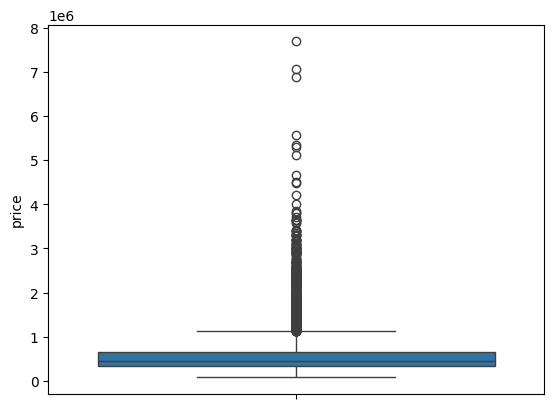

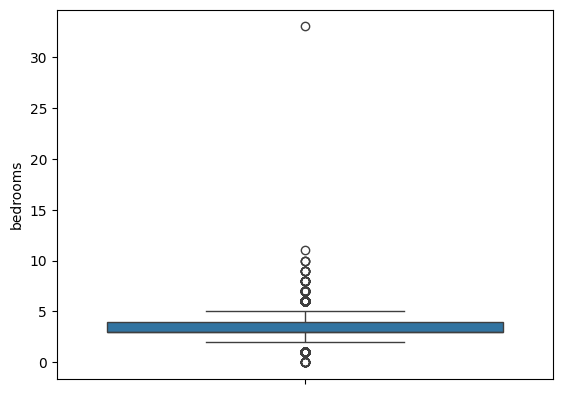

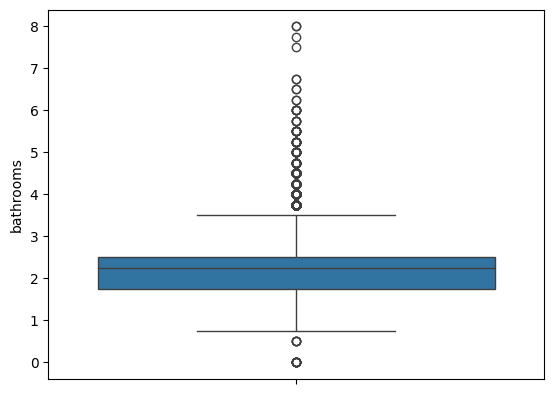

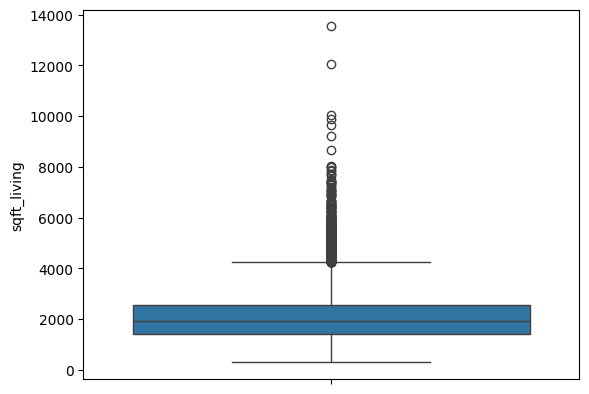

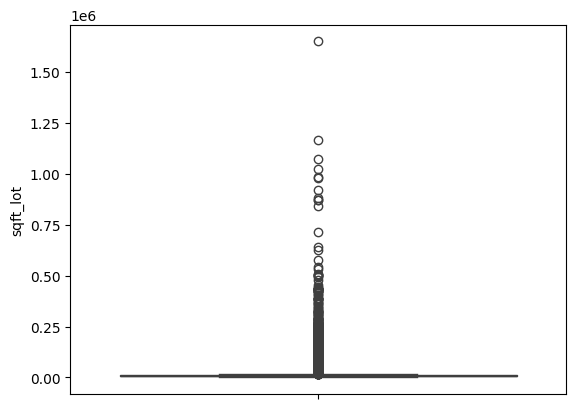

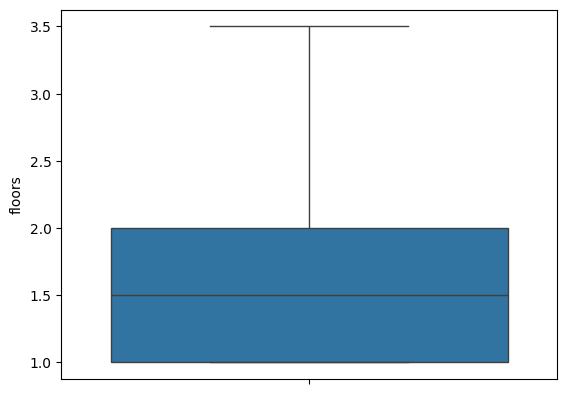

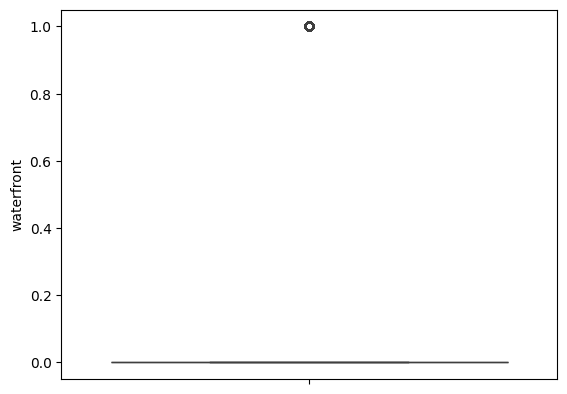

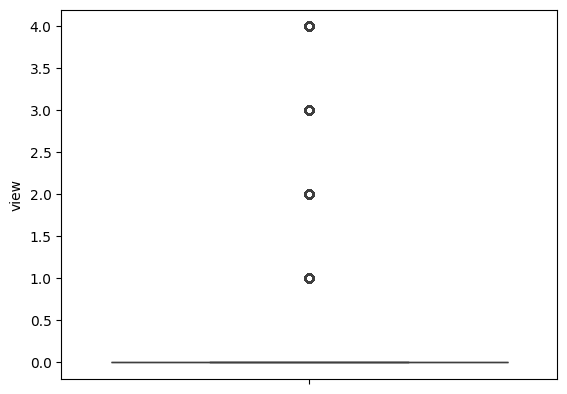

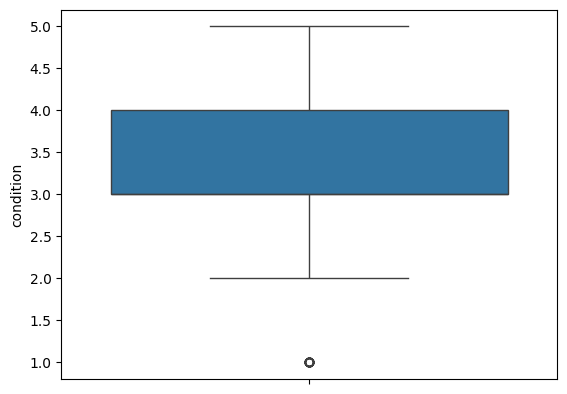

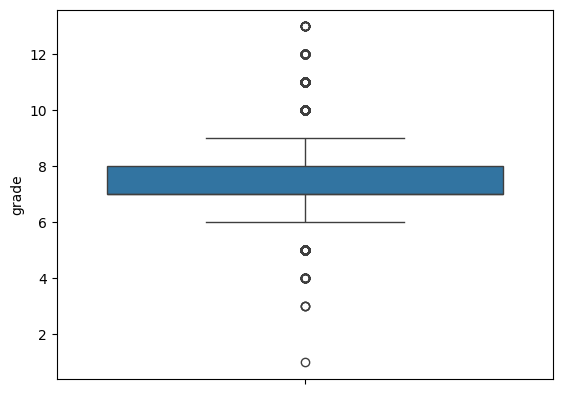

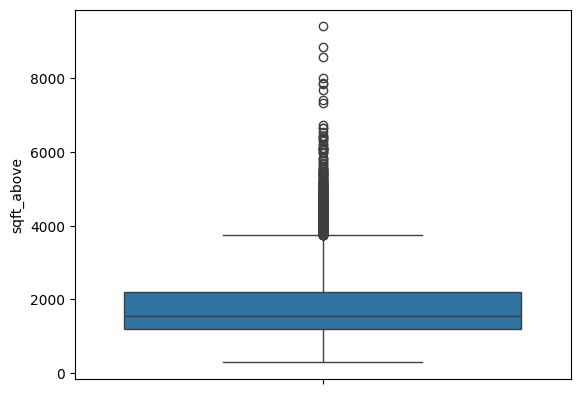

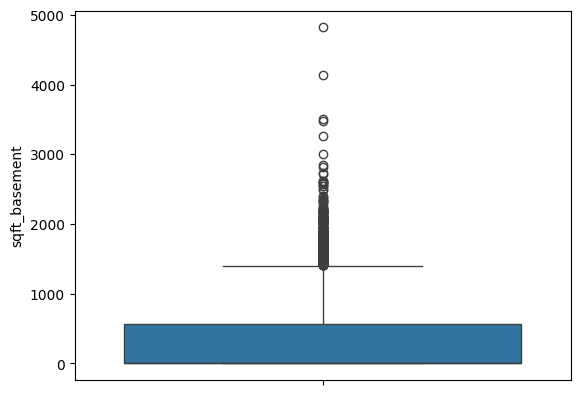

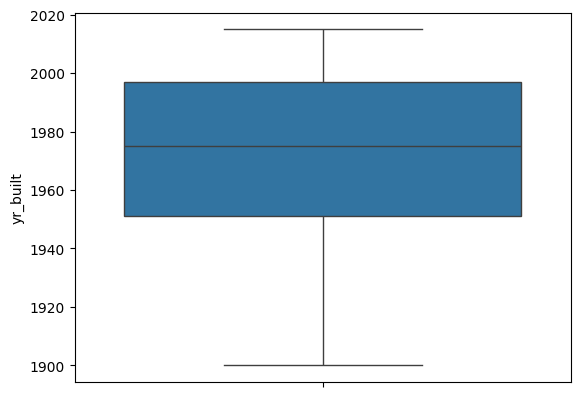

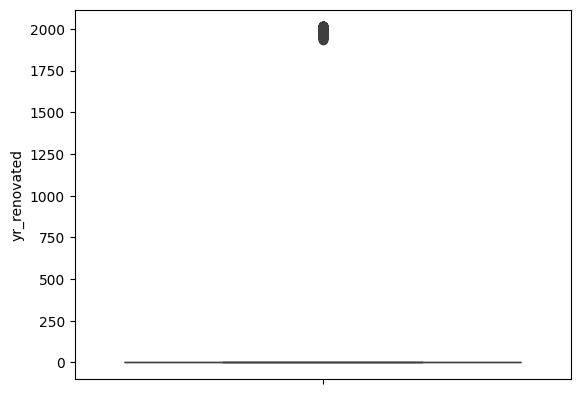

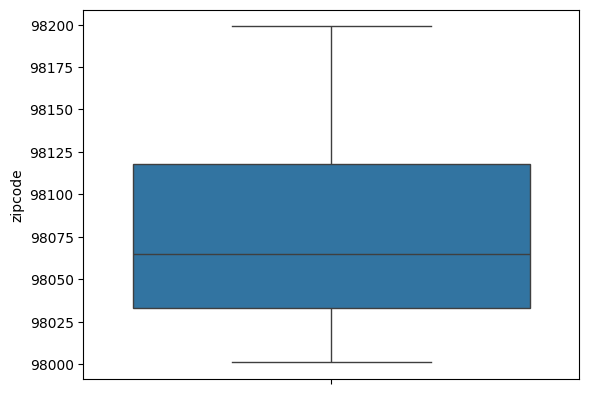

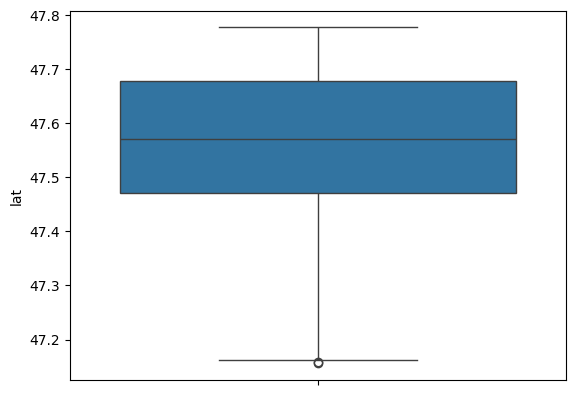

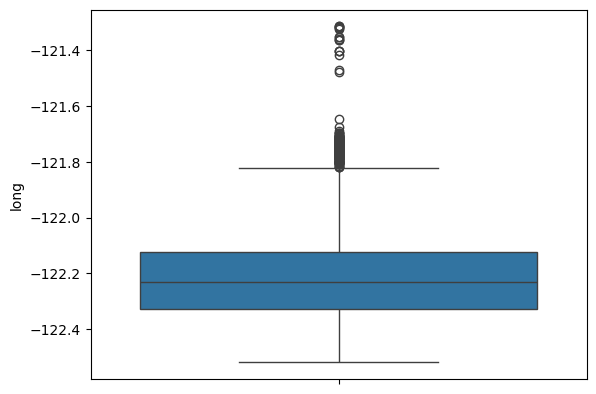

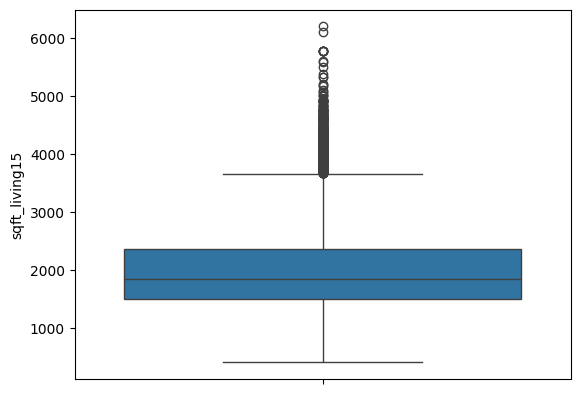

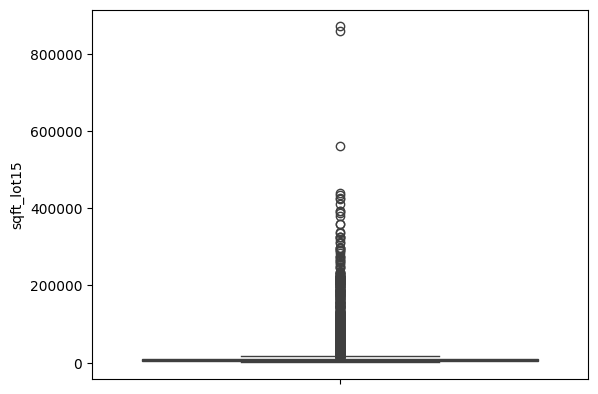

In [ ]:
#checking for outliers
for col in df.columns:
  if df[col].dtype != 'object':
    sns.boxplot(df[col])
    plt.show()

In [ ]:
df[df['bedrooms']>15]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
15870,20140625T000000,640000,33,1.75,1620,6000,1.0,0,0,5,7,1040,580,1947,0,98103,47.6878,-122.331,1330,4700


In [ ]:
df.shape

(21613, 20)

In [ ]:
df.drop(15870,inplace=True)

In [ ]:
df.shape

(21612, 20)

In [ ]:
df[df['bedrooms']>15]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


In [ ]:
df[df['bathrooms']>8]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15


In [ ]:
#fixing the basement area column
df['basement_exists']=(df['sqft_basement']>0).astype(int)
#we are making a new column, if the sqft basement is non zero, that means basement exists

In [ ]:
#before handling renovation year in the similar way, lets convert the date object
# into date and time

In [ ]:
#T -> indicating time so give time in format as well
df['date']=pd.to_datetime(df['date'],format="%Y%m%dT%H%M%S")

In [ ]:
df

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,basement_exists
0,2014-10-13,221900,3,1.00,1180,5650,1.0,0,0,3,...,1180,0,1955,0,98178,47.5112,-122.257,1340,5650,0
1,2014-12-09,538000,3,2.25,2570,7242,2.0,0,0,3,...,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639,1
2,2015-02-25,180000,2,1.00,770,10000,1.0,0,0,3,...,770,0,1933,0,98028,47.7379,-122.233,2720,8062,0
3,2014-12-09,604000,4,3.00,1960,5000,1.0,0,0,5,...,1050,910,1965,0,98136,47.5208,-122.393,1360,5000,1
4,2015-02-18,510000,3,2.00,1680,8080,1.0,0,0,3,...,1680,0,1987,0,98074,47.6168,-122.045,1800,7503,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21608,2014-05-21,360000,3,2.50,1530,1131,3.0,0,0,3,...,1530,0,2009,0,98103,47.6993,-122.346,1530,1509,0
21609,2015-02-23,400000,4,2.50,2310,5813,2.0,0,0,3,...,2310,0,2014,0,98146,47.5107,-122.362,1830,7200,0
21610,2014-06-23,402101,2,0.75,1020,1350,2.0,0,0,3,...,1020,0,2009,0,98144,47.5944,-122.299,1020,2007,0
21611,2015-01-16,400000,3,2.50,1600,2388,2.0,0,0,3,...,1600,0,2004,0,98027,47.5345,-122.069,1410,1287,0


In [ ]:
#extract year of transaction(probably), month and day too

In [ ]:
df['sale_year']=df['date'].dt.year
df['sale_month']=df['date'].dt.month
df['sale_day']=df['date'].dt.day

In [ ]:
#adding whether renovated or no column
df['is_reno']=(df['yr_renovated']>0).astype(int)


In [ ]:
#adding another column, years since renovation
df['since_reno']=0
#initializing to 0

In [ ]:
df.loc[df['yr_renovated'] > 0, 'since_reno'] = (df['sale_year'] - df['yr_renovated'])
#here, the indexing is based on output true/false from if yr_reno>0.
# iloc works only with default indexing, but loc can be used with custom, default and so
# filtering

In [ ]:
df.sample(15)

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,lat,long,sqft_living15,sqft_lot15,basement_exists,sale_year,sale_month,sale_day,is_reno,since_reno
13354,2014-05-20,299950,3,1.00,910,8000,1.0,0,0,4,...,47.7746,-122.378,2090,9007,1,2014,5,20,0,0
10334,2014-06-23,459950,4,2.50,2000,6107,2.0,0,0,3,...,47.7557,-122.221,2040,6520,0,2014,6,23,0,0
15744,2014-11-20,560000,3,2.00,2090,15790,1.0,0,0,3,...,47.7296,-122.199,1820,8770,0,2014,11,20,0,0
4952,2015-01-21,452000,2,1.00,980,5000,1.0,0,0,3,...,47.6744,-122.369,1270,4500,0,2015,1,21,0,0
6329,2014-10-21,240000,3,1.50,1290,8366,1.0,0,0,3,...,47.4853,-122.318,1770,8400,1,2014,10,21,0,0
9464,2014-06-13,250600,4,2.50,1930,8660,1.0,0,0,3,...,47.3261,-122.260,1830,9591,1,2014,6,13,0,0
7613,2014-06-25,275000,2,1.00,770,4840,1.0,0,0,4,...,47.5510,-122.376,930,4840,0,2014,6,25,0,0
5496,2014-06-20,640000,2,1.75,1760,4400,1.0,0,0,4,...,47.6500,-122.340,1330,4180,1,2014,6,20,0,0
457,2014-11-26,705000,3,3.00,1970,20978,2.0,1,3,4,...,47.3844,-122.438,2280,75396,1,2014,11,26,0,0
6886,2014-08-06,509500,5,2.25,2060,9000,1.0,0,0,4,...,47.6122,-122.137,2050,8800,1,2014,8,6,0,0


In [ ]:
df.shape

(21612, 26)

In [ ]:
#quickly run a sanity check for the newly added data

In [ ]:
df.isnull().sum()

,0
date,0
price,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0
condition,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,lat,long,sqft_living15,sqft_lot15,basement_exists,sale_year,sale_month,sale_day,is_reno,since_reno
count,21612,2.161200e+04,21612.000000,21612.000000,21612.000000,2.161200e+04,21612.000000,21612.000000,21612.000000,21612.000000,...,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000
mean,2014-10-29 04:46:26.451971328,5.400835e+05,3.369471,2.114774,2079.921016,1.510739e+04,1.494332,0.007542,0.234314,3.409356,...,47.560047,-122.213891,1986.582871,12768.828984,0.392652,2014.322969,6.574449,15.687766,0.042291,0.779983
min,2014-05-02 00:00:00,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,...,47.155900,-122.519000,399.000000,651.000000,0.000000,2014.000000,1.000000,1.000000,0.000000,-1.000000
25%,2014-07-22 00:00:00,3.218375e+05,3.000000,1.750000,1426.500000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,...,47.470975,-122.328000,1490.000000,5100.000000,0.000000,2014.000000,4.000000,8.000000,0.000000,0.000000
50%,2014-10-16 00:00:00,4.500000e+05,3.000000,2.250000,1910.000000,7.619000e+03,1.500000,0.000000,0.000000,3.000000,...,47.571800,-122.230000,1840.000000,7620.000000,0.000000,2014.000000,6.000000,16.000000,0.000000,0.000000
75%,2015-02-17 00:00:00,6.450000e+05,4.000000,2.500000,2550.000000,1.068825e+04,2.000000,0.000000,0.000000,4.000000,...,47.678000,-122.125000,2360.000000,10083.250000,1.000000,2015.000000,9.000000,23.000000,0.000000,0.000000
max,2015-05-27 00:00:00,7.700000e+06,11.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,...,47.777600,-121.315000,6210.000000,871200.000000,1.000000,2015.000000,12.000000,31.000000,1.000000,80.000000
std,NaN,3.671351e+05,0.907982,0.770177,918.456818,4.142142e+04,0.539991,0.086519,0.766334,0.650668,...,0.138564,0.140829,685.392610,27304.756179,0.488352,0.467622,3.115377,8.635030,0.201258,4.895440


In [ ]:
#there are some -ves in years since renovation, probably renovated after sold or some
# inconsistency
df.loc[df['since_reno'] < 0, 'since_reno'] = 0
#converts -ves to 0

In [ ]:
df.describe()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,lat,long,sqft_living15,sqft_lot15,basement_exists,sale_year,sale_month,sale_day,is_reno,since_reno
count,21612,2.161200e+04,21612.000000,21612.000000,21612.000000,2.161200e+04,21612.000000,21612.000000,21612.000000,21612.000000,...,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000,21612.000000
mean,2014-10-29 04:46:26.451971328,5.400835e+05,3.369471,2.114774,2079.921016,1.510739e+04,1.494332,0.007542,0.234314,3.409356,...,47.560047,-122.213891,1986.582871,12768.828984,0.392652,2014.322969,6.574449,15.687766,0.042291,0.780261
min,2014-05-02 00:00:00,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,...,47.155900,-122.519000,399.000000,651.000000,0.000000,2014.000000,1.000000,1.000000,0.000000,0.000000
25%,2014-07-22 00:00:00,3.218375e+05,3.000000,1.750000,1426.500000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,...,47.470975,-122.328000,1490.000000,5100.000000,0.000000,2014.000000,4.000000,8.000000,0.000000,0.000000
50%,2014-10-16 00:00:00,4.500000e+05,3.000000,2.250000,1910.000000,7.619000e+03,1.500000,0.000000,0.000000,3.000000,...,47.571800,-122.230000,1840.000000,7620.000000,0.000000,2014.000000,6.000000,16.000000,0.000000,0.000000
75%,2015-02-17 00:00:00,6.450000e+05,4.000000,2.500000,2550.000000,1.068825e+04,2.000000,0.000000,0.000000,4.000000,...,47.678000,-122.125000,2360.000000,10083.250000,1.000000,2015.000000,9.000000,23.000000,0.000000,0.000000
max,2015-05-27 00:00:00,7.700000e+06,11.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,...,47.777600,-121.315000,6210.000000,871200.000000,1.000000,2015.000000,12.000000,31.000000,1.000000,80.000000
std,NaN,3.671351e+05,0.907982,0.770177,918.456818,4.142142e+04,0.539991,0.086519,0.766334,0.650668,...,0.138564,0.140829,685.392610,27304.756179,0.488352,0.467622,3.115377,8.635030,0.201258,4.895367


In [ ]:
#data is more or less cleaned

#VIF Cleaning

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']

In [ ]:
x.values

array([[3.00e+00, 1.00e+00, 1.18e+03, ..., 1.30e+01, 0.00e+00, 0.00e+00],
       [3.00e+00, 2.25e+00, 2.57e+03, ..., 9.00e+00, 1.00e+00, 2.30e+01],
       [2.00e+00, 1.00e+00, 7.70e+02, ..., 2.50e+01, 0.00e+00, 0.00e+00],
       ...,
       [2.00e+00, 7.50e-01, 1.02e+03, ..., 2.30e+01, 0.00e+00, 0.00e+00],
       [3.00e+00, 2.50e+00, 1.60e+03, ..., 1.60e+01, 0.00e+00, 0.00e+00],
       [2.00e+00, 7.50e-01, 1.02e+03, ..., 1.50e+01, 0.00e+00, 0.00e+00]])

In [ ]:
vif_data=pd.DataFrame()
#empty data frame for vif values

In [ ]:
x.isna().sum()

,0
bedrooms,0
bathrooms,0
sqft_living,0
sqft_lot,0
floors,0
waterfront,0
view,0
condition,0
grade,0
sqft_above,0


In [ ]:
x.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21612 entries, 0 to 21612
Data columns (total 24 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bedrooms         21612 non-null  int64  
 1   bathrooms        21612 non-null  float64
 2   sqft_living      21612 non-null  int64  
 3   sqft_lot         21612 non-null  int64  
 4   floors           21612 non-null  float64
 5   waterfront       21612 non-null  int64  
 6   view             21612 non-null  int64  
 7   condition        21612 non-null  int64  
 8   grade            21612 non-null  int64  
 9   sqft_above       21612 non-null  int64  
 10  sqft_basement    21612 non-null  int64  
 11  yr_built         21612 non-null  int64  
 12  yr_renovated     21612 non-null  int64  
 13  zipcode          21612 non-null  int64  
 14  lat              21612 non-null  float64
 15  long             21612 non-null  float64
 16  sqft_living15    21612 non-null  int64  
 17  sqft_lot15       

In [ ]:
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

/usr/local/lib/python3.12/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


In [ ]:
vif_data

,col,VIF values
0,bedrooms,2.524307e+01
1,bathrooms,2.923385e+01
2,sqft_living,inf
3,sqft_lot,2.382872e+00
4,floors,1.741125e+01
5,waterfront,1.216150e+00
6,view,1.571929e+00
7,condition,3.555698e+01
8,grade,1.501135e+02
9,sqft_above,inf


In [ ]:
#inf values -> removing sqft below and  sqft basement as info is already provided
# in the plot area and living area
df.drop('sqft_above',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]
#repeat

In [ ]:
vif_data

,col,VIF values
0,bedrooms,2.524307e+01
1,bathrooms,2.923385e+01
2,sqft_living,3.960734e+01
3,sqft_lot,2.382872e+00
4,floors,1.741125e+01
5,waterfront,1.216150e+00
6,view,1.571929e+00
7,condition,3.555698e+01
8,grade,1.501135e+02
9,sqft_basement,6.958349e+00


In [ ]:
#upon checking the columns, is reno and year reno have high

In [ ]:
df.drop('yr_renovated',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.524124e+01
1,bathrooms,2.923218e+01
2,sqft_living,3.960229e+01
3,sqft_lot,2.382848e+00
4,floors,1.741118e+01
5,waterfront,1.216120e+00
6,view,1.571471e+00
7,condition,3.554828e+01
8,grade,1.501102e+02
9,sqft_basement,6.957909e+00


In [ ]:
#zipcode,long and lat have most vif factors
#zipcode helps identify the location and lat and long are not needed or vice versa

In [ ]:
df.drop('lat',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.520329e+01
1,bathrooms,2.922406e+01
2,sqft_living,3.944959e+01
3,sqft_lot,2.380083e+00
4,floors,1.729374e+01
5,waterfront,1.216036e+00
6,view,1.558836e+00
7,condition,3.545497e+01
8,grade,1.462888e+02
9,sqft_basement,6.944313e+00


In [ ]:
df.drop('long',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.519842e+01
1,bathrooms,2.922024e+01
2,sqft_living,3.913386e+01
3,sqft_lot,2.369697e+00
4,floors,1.718138e+01
5,waterfront,1.215561e+00
6,view,1.554457e+00
7,condition,3.545417e+01
8,grade,1.433538e+02
9,sqft_basement,6.925679e+00


In [ ]:
#remove sale month and day even though they have less values since they are too small
# timr intervals to decide price

In [ ]:
df.drop('sale_month',axis=1,inplace=True)
df.drop('sale_day',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.519440e+01
1,bathrooms,2.921855e+01
2,sqft_living,3.911963e+01
3,sqft_lot,2.369587e+00
4,floors,1.714992e+01
5,waterfront,1.215313e+00
6,view,1.550839e+00
7,condition,3.529367e+01
8,grade,1.432616e+02
9,sqft_basement,6.925182e+00


In [ ]:
#removing size redundancies
df.drop('sqft_living15',axis=1,inplace=True)
df.drop('sqft_lot15',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.513133e+01
1,bathrooms,2.916477e+01
2,sqft_living,3.214044e+01
3,sqft_lot,1.210818e+00
4,floors,1.682175e+01
5,waterfront,1.213898e+00
6,view,1.518669e+00
7,condition,3.523878e+01
8,grade,1.319953e+02
9,sqft_basement,6.830159e+00


In [ ]:
#remove quality redundancy
df.drop('grade',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.456408e+01
1,bathrooms,2.902988e+01
2,sqft_living,2.136846e+01
3,sqft_lot,1.208676e+00
4,floors,1.668764e+01
5,waterfront,1.212737e+00
6,view,1.493000e+00
7,condition,3.523248e+01
8,sqft_basement,6.592540e+00
9,yr_built,9.480360e+03


In [ ]:
#remove time redundancy
df.drop('since_reno',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.456276e+01
1,bathrooms,2.897185e+01
2,sqft_living,2.135701e+01
3,sqft_lot,1.208510e+00
4,floors,1.668219e+01
5,waterfront,1.210220e+00
6,view,1.492795e+00
7,condition,3.511136e+01
8,sqft_basement,6.584254e+00
9,yr_built,9.480094e+03


In [ ]:
#year built is useful information and its vif dropped after since reno was removed

In [ ]:
#removing basement area also, all areas are covered by plot area
df.drop('sqft_basement',axis=1,inplace=True)

In [ ]:
x=df.drop(['price','date'],axis=1)
y=df['price']
vif_data=pd.DataFrame()
vif_data['col']=x.columns
vif_data['VIF values']=[variance_inflation_factor(x.values,i)for i in range(len(x.columns))]

vif_data

,col,VIF values
0,bedrooms,2.451031e+01
1,bathrooms,2.897029e+01
2,sqft_living,1.801343e+01
3,sqft_lot,1.205694e+00
4,floors,1.543641e+01
5,waterfront,1.210219e+00
6,view,1.476693e+00
7,condition,3.483242e+01
8,yr_built,9.474619e+03
9,zipcode,3.466039e+06


#Model Building

In [ ]:
df.drop('date',axis=1,inplace=True)

In [ ]:
x1=df.drop('price',axis=1)
y1=df['price']

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x1,y1,test_size=0.25,random_state=39)

In [ ]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()

In [ ]:
model.fit(x_train,y_train)

LinearRegression()

In [ ]:
y_predict=model.predict(x_test)
y_predict

array([ 961851.8113772 ,  914197.25517218, 1089263.29305144, ...,
        407667.1962875 ,  149590.42285071,  503499.52636109])

In [ ]:
#checking r2 score for accuracy

In [ ]:
from sklearn.metrics import r2_score
print(r2_score(y_test,y_predict))


0.581586280013245
